In [1]:
%pip -q install rpy2
%load_ext rpy2.ipython
print("R magic is ready. Run the R cells below.")

R magic is ready. Run the R cells below.


# Week 11 — Data Frames, Data Handling and Statistical Functions

## 1. Data-frame inspection and summaries

In [2]:
%%R
# Use a built-in dataset to avoid needing a separate download.
data(iris)
head(iris)
str(iris)
dim(iris)
names(iris)
summary(iris)

# Frequency table for a categorical variable
table(iris$Species)
prop.table(table(iris$Species))

'data.frame':	150 obs. of  5 variables:
 $ Sepal.Length: num  5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
 $ Sepal.Width : num  3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
 $ Petal.Length: num  1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
 $ Petal.Width : num  0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 1 1 1 1 1 1 1 ...

    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 


## 2. Subsetting, selecting columns and splitting data

In [3]:
%%R
# Filter rows using subset()
setosa <- subset(iris, Species == "setosa")
head(setosa)

# Equivalent row filtering and column selection
iris[iris$Sepal.Length > 6, c("Sepal.Length", "Sepal.Width", "Species")]

# Remove selected columns by selecting the columns to keep
subset(iris, Species == "virginica", select = c(Sepal.Length, Petal.Length, Species))

# Split a data frame by a factor/categorical variable
iris_split <- split(iris, iris$Species)
names(iris_split)
lapply(iris_split, nrow)

$setosa
[1] 50

$versicolor
[1] 50

$virginica
[1] 50



## 3. Importing CSV and Excel data

In [4]:
%%R
# Create a sample CSV, then import it. Replace this path with your own uploaded CSV if needed.
sample_data <- data.frame(
  Name = c("Asha", "Ravi", "Neha", "Omar"),
  Score = c(78, 85, 92, 73),
  Group = c("A", "A", "B", "B")
)
write.csv(sample_data, "/content/sample_data.csv", row.names = FALSE)
csv_data <- read.csv("/content/sample_data.csv")
print(csv_data)

# Excel import from the notes uses readxl.
# Uncomment to install/load and read an Excel file you have uploaded:
# install.packages("readxl")
# library(readxl)
# excel_data <- read_excel("/content/your_file.xlsx", sheet = 1)

  Name Score Group
1 Asha    78     A
2 Ravi    85     A
3 Neha    92     B
4 Omar    73     B


## 4. Saving and writing data files

In [5]:
%%R
write.csv(iris, "/content/iris_export.csv", row.names = FALSE)
write.table(head(iris), "/content/iris_sample.txt",
            sep = "\t", row.names = FALSE, quote = FALSE)

file.exists("/content/iris_export.csv")
file.info("/content/iris_export.csv")[, c("size", "mtime")]

                         size               mtime
/content/iris_export.csv 4026 2026-10-19 21:46:38


## 5. Descriptive statistics and partition values

In [6]:
%%R
marks <- c(68, 82, 63, 86, 34, 96, 41, 89, 29, 51, 75, 77, 56, 59, 42)

mean(marks)
median(marks)
sd(marks)
var(marks)
range(marks)
summary(marks)

# Absolute and relative frequencies
gender <- c(1, 2, 1, 2, 1, 1, 1, 2, 1, 1)
table(gender)
prop.table(table(gender))

# Quantiles / quartiles
quantile(marks)
quantile(marks, probs = c(0, 0.25, 0.5, 0.75, 1))

  0%  25%  50%  75% 100% 
29.0 46.5 63.0 79.5 96.0 


## 6. Scatter plot and bar plot

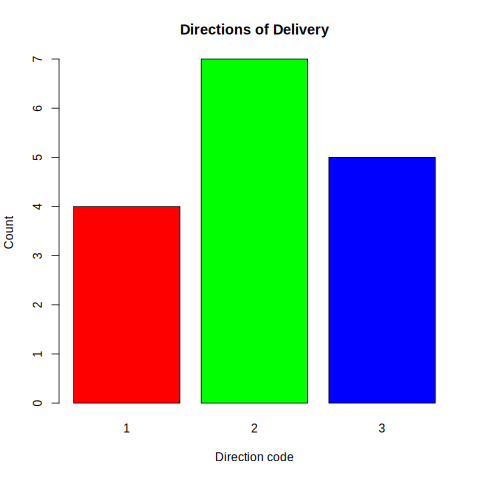

In [7]:
%%R
# One-variable plot and bar plot of categorical frequencies
height <- c(166, 125, 130, 142, 147, 159, 159, 147, 165, 156,
            149, 164, 137, 166, 135, 142)
plot(height, main = "Recorded Heights", xlab = "Observation", ylab = "Height (cm)",
     pch = 19, col = "blue")

barplot(table(gender), main = "Gender Frequency",
        xlab = "Category code", ylab = "Frequency",
        col = c("tomato", "skyblue"))

direction <- c(1, 1, 2, 1, 2, 3, 2, 2, 3, 3, 3, 1, 2, 3, 2, 2)
barplot(table(direction), col = c("red", "green", "blue"),
        main = "Directions of Delivery", xlab = "Direction code", ylab = "Count")